<a href="https://colab.research.google.com/github/ayishathanha53-eng/AI-ML-lab/blob/main/ai_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#lab cycle 1-AI/ML
# step 1
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing libraries
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

# Train test split
from sklearn.model_selection import train_test_split

# Data balancing
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.linear_model import LinearRegression

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("carsensor.csv")
df.head()




,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
0,Hatchback,10,7984,85,1144,36,19.2,12.65,27,32
1,Sedan,5,132389,86,1660,34,14.4,11.90,34,33
2,SUV,10,158617,101,2588,26,10.9,12.43,43,31
3,SUV,5,54477,99,2762,39,10.3,11.89,29,29
4,Sedan,3,122035,102,2146,41,13.0,12.09,44,36


In [2]:
#step 2
# Display number of rows and columns
print("Shape of dataset:", df.shape)

# Display information about the dataset
df.info()

# Display statistical summary
df.describe()



Shape of dataset: (12000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Vehicle_Type      12000 non-null  object 
 1   Vehicle_Age       12000 non-null  int64  
 2   Mileage           12000 non-null  int64  
 3   Engine_Temp       12000 non-null  int64  
 4   RPM               12000 non-null  int64  
 5   Oil_Pressure      12000 non-null  int64  
 6   Fuel_Consumption  12000 non-null  float64
 7   Battery_Voltage   12000 non-null  float64
 8   Brake_Pressure    12000 non-null  int64  
 9   Tire_Pressure     12000 non-null  int64  
dtypes: float64(2), int64(7), object(1)
memory usage: 937.6+ KB


,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,6.510917,127103.114750,96.646583,2032.028417,32.867917,12.743142,12.252960,34.866667,32.065167
std,3.444034,70927.072506,7.478403,832.281923,6.603656,4.651146,0.317925,6.034616,2.566704
min,1.000000,5048.000000,82.000000,600.000000,15.000000,2.600000,11.700000,25.000000,28.000000
25%,4.000000,65346.000000,91.000000,1318.000000,29.000000,9.000000,11.980000,30.000000,30.000000
50%,7.000000,126630.500000,96.000000,2032.000000,33.000000,13.000000,12.260000,35.000000,32.000000
75%,10.000000,188185.750000,101.000000,2737.000000,38.000000,16.300000,12.530000,40.000000,34.000000
max,12.000000,250000.000000,118.000000,3500.000000,48.000000,23.300000,12.800000,45.000000,36.000000


In [3]:
#display missing values
df.isnull().sum()

,0
Vehicle_Type,0
Vehicle_Age,0
Mileage,0
Engine_Temp,0
RPM,0
Oil_Pressure,0
Fuel_Consumption,0
Battery_Voltage,0
Brake_Pressure,0
Tire_Pressure,0


In [4]:
# step 3
# First 5 records
df.head()

# Last 5 records
df.tail()

# Random 5 records
df.sample(5)

,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
7956,SUV,4,68174,99,1315,42,11.0,12.38,27,28
4223,Sedan,1,14726,95,1908,34,16.4,12.60,28,32
1385,Hatchback,7,26895,91,1506,41,20.2,11.76,33,29
666,SUV,7,242305,95,1252,23,12.5,11.93,37,36
4617,Truck,4,57720,95,3242,25,8.8,12.53,38,28


In [5]:
# step 4
#fill missing values with mean
num_cols = ['Vehicle_Age', 'Mileage', 'Engine_Temp', 'RPM',
            'Oil_Pressure', 'Fuel_Consumption',
            'Battery_Voltage', 'Brake_Pressure', 'Tire_Pressure']

df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

In [6]:
#fill missing values with mode
# df['Vehicle_Type'].fillna(df['Vehicle_Type'].mode()[0], inplace=True)

In [7]:
# check no missing value
print(df.isnull().sum())

Vehicle_Type        0
Vehicle_Age         0
Mileage             0
Engine_Temp         0
RPM                 0
Oil_Pressure        0
Fuel_Consumption    0
Battery_Voltage     0
Brake_Pressure      0
Tire_Pressure       0
dtype: int64


In [8]:
# step 5
# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Verify duplicates are removed
print("Duplicate Rows After Removal:", df.duplicated().sum())

Duplicate Rows: 0
Duplicate Rows After Removal: 0


In [9]:
# step 6 - Detect Outliers Using IQR and Visualize with Box Plot
Q1 = df['Engine_Temp'].quantile(0.25)
Q3 = df['Engine_Temp'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Engine_Temp'] < lower) | (df['Engine_Temp'] > upper)]

print(outliers)


      Vehicle_Type  Vehicle_Age  Mileage  Engine_Temp   RPM  Oil_Pressure  \
55           Truck           10   137460          117  1332            36   
350          Truck           11   119349          117  2607            18   
897          Truck            6   192930          118  2242            15   
974          Truck           12   153047          117  2539            32   
1230         Truck            9   213546          117  2963            26   
1330         Truck           12    60877          117  2220            28   
1461         Truck           10   102498          117  2515            36   
1554         Truck            3   193031          118   606            31   
1719         Truck            2   102858          117  1725            20   
2091         Truck            8   177658          117  2133            27   
2324         Truck            7   171992          118  2911            21   
2829         Truck           11   145281          117  1538            22   

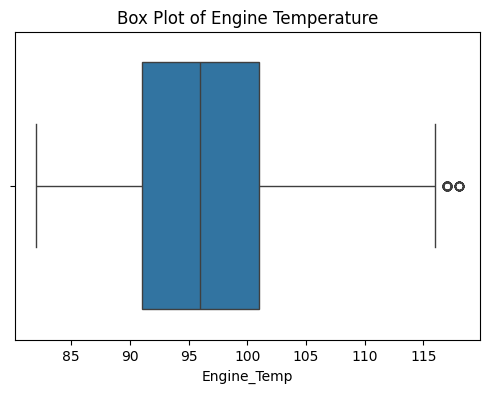

In [10]:
# box plot
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Engine_Temp'])
plt.title("Box Plot of Engine Temperature")
plt.show()

In [11]:
#Step 7: Handle Outliers
df = df[(df['Engine_Temp'] >= lower) & (df['Engine_Temp'] <= upper)]


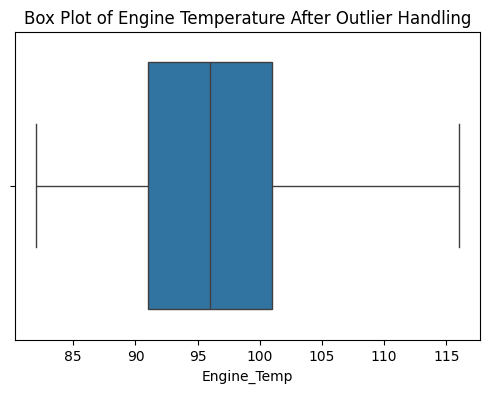

In [12]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Engine_Temp'])
plt.title("Box Plot of Engine Temperature After Outlier Handling")
plt.show()

In [13]:
# step 8
#Label Encoding
from sklearn.preprocessing import LabelEncoder

# Create encoder
le = LabelEncoder()

# Apply label encoding
# df['Vehicle_Type_Label'] = le.fit_transform(df['Vehicle_Type'])

# Display result
# df[['Vehicle_Type','Vehicle_Type_Label']].head()
# The 'Vehicle_Type_Label' column already exists in the DataFrame, so this step is redundant.

In [14]:
# Apply One-Hot Encoding

# df = pd.get_dummies(df, columns=['Vehicle_Type'])

# Display columns
df.head()

,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
0,Hatchback,10,7984,85,1144,36,19.2,12.65,27,32
1,Sedan,5,132389,86,1660,34,14.4,11.90,34,33
2,SUV,10,158617,101,2588,26,10.9,12.43,43,31
3,SUV,5,54477,99,2762,39,10.3,11.89,29,29
4,Sedan,3,122035,102,2146,41,13.0,12.09,44,36


In [15]:
# step 9
# min-max
from sklearn.preprocessing import MinMaxScaler

# Select numerical columns
num_cols = ['Vehicle_Age', 'Mileage', 'Engine_Temp', 'RPM',
            'Oil_Pressure', 'Fuel_Consumption',
            'Battery_Voltage', 'Brake_Pressure',
            'Tire_Pressure']

# Create scaler
minmax = MinMaxScaler()

# Apply Min-Max normalization
df[num_cols] = minmax.fit_transform(df[num_cols])

# Display scaled data
df.head()

,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
0,Hatchback,0.818182,0.011986,0.088235,0.187586,0.636364,0.801932,0.863636,0.10,0.500
1,Sedan,0.363636,0.519861,0.117647,0.365517,0.575758,0.570048,0.181818,0.45,0.625
2,SUV,0.818182,0.626935,0.558824,0.685517,0.333333,0.400966,0.663636,0.90,0.375
3,SUV,0.363636,0.201791,0.500000,0.745517,0.727273,0.371981,0.172727,0.20,0.125
4,Sedan,0.181818,0.477592,0.588235,0.533103,0.787879,0.502415,0.354545,0.95,1.000


In [16]:
#z score
from sklearn.preprocessing import StandardScaler

# Create standard scaler
standard = StandardScaler()

# Apply standardization
df[num_cols] = standard.fit_transform(df[num_cols])

# Display result
df.head()

,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
0,Hatchback,1.012242,-1.679467,-1.570046,-1.066749,0.470386,1.384383,1.249491,-1.304526,-0.024930
1,Sedan,-0.439411,0.074088,-1.434027,-0.446663,0.166977,0.350863,-1.109227,-0.144275,0.364678
2,SUV,1.012242,0.443785,0.606251,0.668531,-1.046659,-0.402745,0.557600,1.347477,-0.414537
3,SUV,-0.439411,-1.024123,0.334214,0.877630,0.925499,-0.531935,-1.140676,-0.973026,-1.193753
4,Sedan,-1.020071,-0.071858,0.742269,0.137372,1.228908,0.049420,-0.511685,1.513227,1.533502


In [17]:
#step 10 ,correlation matrix
correlation = df.corr(numeric_only=True)

correlation

,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure
Vehicle_Age,1.000000,-0.007839,-0.006904,0.013913,0.003583,0.000632,0.013853,-0.005456,0.000888
Mileage,-0.007839,1.000000,0.009410,-0.009590,-0.000763,-0.008856,-0.017494,-0.003428,0.004440
Engine_Temp,-0.006904,0.009410,1.000000,-0.023456,-0.444563,-0.618042,0.006358,0.001580,-0.017335
RPM,0.013913,-0.009590,-0.023456,1.000000,0.010743,0.026410,0.003397,0.011563,-0.017019
Oil_Pressure,0.003583,-0.000763,-0.444563,0.010743,1.000000,0.553226,0.002056,0.008140,0.014147
Fuel_Consumption,0.000632,-0.008856,-0.618042,0.026410,0.553226,1.000000,-0.004396,-0.007556,0.005723
Battery_Voltage,0.013853,-0.017494,0.006358,0.003397,0.002056,-0.004396,1.000000,0.006752,0.011363
Brake_Pressure,-0.005456,-0.003428,0.001580,0.011563,0.008140,-0.007556,0.006752,1.000000,-0.001390
Tire_Pressure,0.000888,0.004440,-0.017335,-0.017019,0.014147,0.005723,0.011363,-0.001390,1.000000


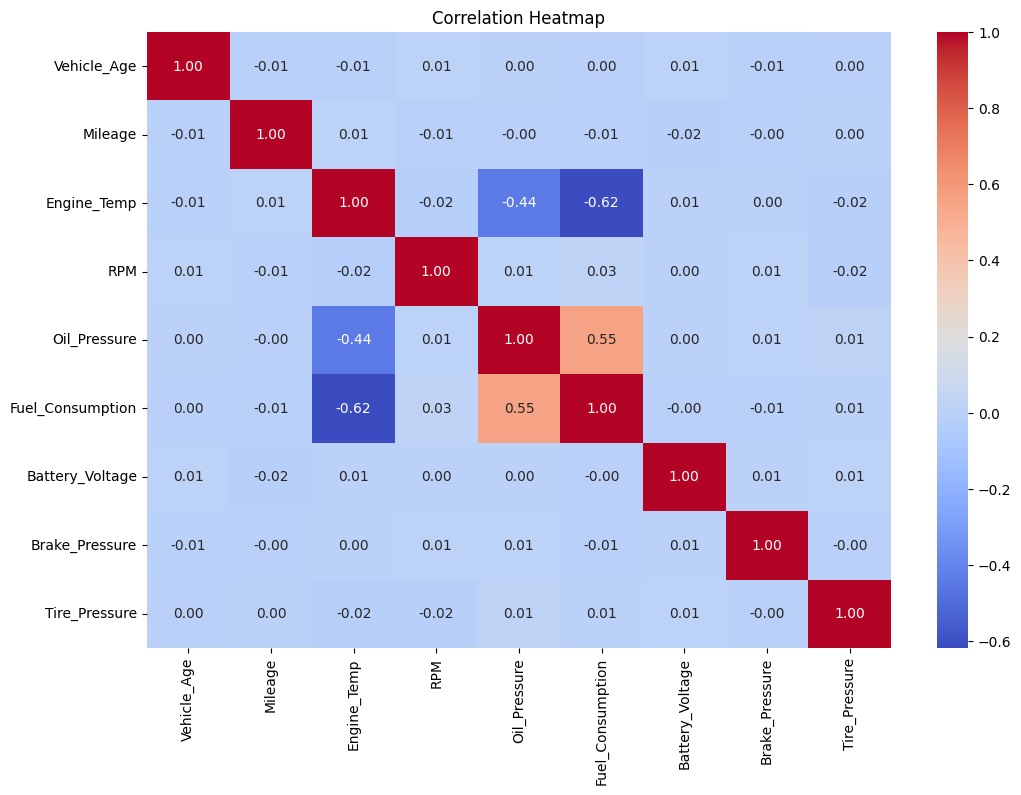

In [18]:
#step 11 correlation heatmap
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [19]:
# step 12
# feature 1- Engine Performance Score safely computed
# Adding a small constant epsilon to avoid division by zero if standardized values are close to zero
epsilon = 1e-5
df['Engine_Performance_Score'] = df['RPM'] / (df['Engine_Temp'].abs() + epsilon)

df[['RPM','Engine_Temp','Engine_Performance_Score']].head()

,RPM,Engine_Temp,Engine_Performance_Score
0,-1.066749,-1.570046,-0.679434
1,-0.446663,-1.434027,-0.311472
2,0.668531,0.606251,1.102711
3,0.877630,0.334214,2.625874
4,0.137372,0.742269,0.185067


In [20]:
#Feature 2: Vehicle Efficiency
df['Vehicle_Efficiency'] = df['Mileage'] / (df['Fuel_Consumption'].abs() + epsilon)
df[['Mileage','Fuel_Consumption','Vehicle_Efficiency']].head()

,Mileage,Fuel_Consumption,Vehicle_Efficiency
0,-1.679467,1.384383,-1.213143
1,0.074088,0.350863,0.211152
2,0.443785,-0.402745,1.101874
3,-1.024123,-0.531935,-1.925243
4,-0.071858,0.049420,-1.453722


In [21]:
#Feature 3: Average Pressure
df['Average_Pressure'] = (
    df['Oil_Pressure'] +
    df['Brake_Pressure'] +
    df['Tire_Pressure']
) / 3

df[['Oil_Pressure',
    'Brake_Pressure',
    'Tire_Pressure',
    'Average_Pressure']].head()

,Oil_Pressure,Brake_Pressure,Tire_Pressure,Average_Pressure
0,0.470386,-1.304526,-0.024930,-0.286357
1,0.166977,-0.144275,0.364678,0.129127
2,-1.046659,1.347477,-0.414537,-0.037907
3,0.925499,-0.973026,-1.193753,-0.413760
4,1.228908,1.513227,1.533502,1.425212


In [22]:
# step 13
df.dtypes

,0
Vehicle_Type,object
Vehicle_Age,float64
Mileage,float64
Engine_Temp,float64
RPM,float64
Oil_Pressure,float64
Fuel_Consumption,float64
Battery_Voltage,float64
Brake_Pressure,float64
Tire_Pressure,float64


In [23]:
#Convert Boolean Values to Integer
bool_cols = df.select_dtypes(include='bool').columns

df[bool_cols] = df[bool_cols].astype(int)

df.dtypes


,0
Vehicle_Type,object
Vehicle_Age,float64
Mileage,float64
Engine_Temp,float64
RPM,float64
Oil_Pressure,float64
Fuel_Consumption,float64
Battery_Voltage,float64
Brake_Pressure,float64
Tire_Pressure,float64


In [24]:
# step 14
df.describe()

,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure,Engine_Performance_Score,Vehicle_Efficiency,Average_Pressure
count,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,1.194000e+04,11940.000000,11940.000000,1.194000e+04
mean,-1.011661e-17,-1.142581e-16,-3.999034e-16,-6.322878e-17,-1.832891e-16,-1.785283e-16,-2.157217e-16,-2.053076e-16,1.356815e-16,-0.066253,-0.117849,-8.688379e-17
std,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,5.229446,15.172506,5.813824e-01
min,-1.600732e+00,-1.720851e+00,-1.978101e+00,-1.720484e+00,-2.715409e+00,-2.189873e+00,-1.738218e+00,-1.636027e+00,-1.583361e+00,-27.569824,-267.432950,-1.877129e+00
25%,-7.297410e-01,-8.710953e-01,-7.539346e-01,-8.576504e-01,-5.915458e-01,-8.118466e-01,-8.576303e-01,-8.072756e-01,-8.041453e-01,-1.163067,-1.068352,-4.000623e-01
50%,1.412504e-01,-6.306284e-03,-7.384189e-02,-8.259040e-04,1.527209e-02,4.942004e-02,2.295766e-02,2.147534e-02,-2.492968e-02,-0.001761,-0.009638,6.600971e-03
75%,1.012242e+00,8.611608e-01,6.062508e-01,8.475866e-01,7.737945e-01,7.599650e-01,8.720961e-01,8.502263e-01,7.542859e-01,1.135590,1.059746,4.048958e-01
max,1.592903e+00,1.731877e+00,2.646529e+00,1.764497e+00,2.290839e+00,2.267182e+00,1.721234e+00,1.678977e+00,1.533502e+00,28.374210,271.502637,1.733303e+00


In [25]:
#14.1 Check duplicate values again
df.duplicated().sum()
#14.2 check for infinite values
import numpy as np

df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [26]:
#14.3 Handle new feature outliers
#For Engine Performance Score:

Q1 = df['Engine_Performance_Score'].quantile(0.25)
Q3 = df['Engine_Performance_Score'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['Engine_Performance_Score'] >= lower) &
    (df['Engine_Performance_Score'] <= upper)
]

#For Vehicle Efficiency:
Q1 = df['Vehicle_Efficiency'].quantile(0.25)
Q3 = df['Vehicle_Efficiency'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['Vehicle_Efficiency'] >= lower) &
    (df['Vehicle_Efficiency'] <= upper)
]

df.describe()

,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure,Engine_Performance_Score,Vehicle_Efficiency,Average_Pressure
count,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000,8818.000000
mean,-0.006648,0.002555,0.039425,0.004385,-0.041673,-0.015822,-0.003431,0.008787,0.004541,0.013961,-0.000715,-0.009448
std,1.003506,0.963624,1.104635,0.955397,1.035804,1.082502,0.997971,0.996697,0.999374,1.611402,1.449653,0.588844
min,-1.600732,-1.720851,-1.978101,-1.720484,-2.715409,-2.189873,-1.738218,-1.636027,-1.583361,-4.602343,-4.195657,-1.877129
25%,-1.020071,-0.800727,-0.889953,-0.781942,-0.743250,-0.941037,-0.857630,-0.807276,-0.804145,-0.926807,-0.872443,-0.413760
50%,0.141250,0.000593,-0.209860,0.014196,0.015272,0.135547,0.007233,0.021475,-0.024930,0.018782,0.000698,-0.001634
75%,1.012242,0.806417,0.742269,0.778788,0.773795,0.867623,0.872096,0.850226,0.754286,0.926829,0.894037,0.399121
max,1.592903,1.731877,2.646529,1.764497,2.290839,2.267182,1.721234,1.678977,1.533502,4.582588,4.181714,1.733303


In [27]:
#Step 15: Split Dataset into Training and Testing Sets using Scikit-learn
#15.1 Create Target Variable

# We check if Vehicle_Efficiency is below its median to tag low efficiency
median_efficiency = df['Vehicle_Efficiency'].median()
df['Vehicle_Status'] = np.where(
    df['Vehicle_Efficiency'] < median_efficiency,
    1,
    0
)

df.head()

#0 → Normal vehicle condition, 1 → Requires maintenance
print(df['Vehicle_Status'].value_counts()) # distribution

Vehicle_Status
1    4409
0    4409
Name: count, dtype: int64


In [28]:
#15.2 Separate Features and Target
# Drop non-numeric columns and target variable
X = df.drop(columns=['Vehicle_Status', 'Vehicle_Type'], errors='ignore')

# Target variable
y = df['Vehicle_Status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (8818, 12)
Target shape: (8818,)


In [29]:
#15.3 Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7054, 12)
Testing data: (1764, 12)


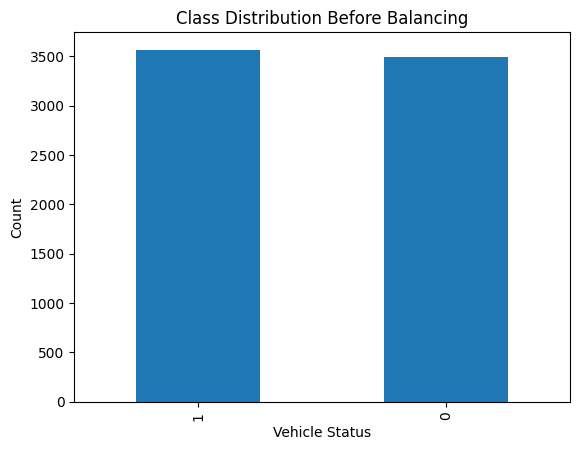

In [30]:
#Step 16: Data Balancing Using Random Oversampling / SMOTE
y_train.value_counts()#imbalance
import matplotlib.pyplot as plt

y_train.value_counts().plot(kind='bar')

plt.xlabel("Vehicle Status")
plt.ylabel("Count")
plt.title("Class Distribution Before Balancing")

plt.show()

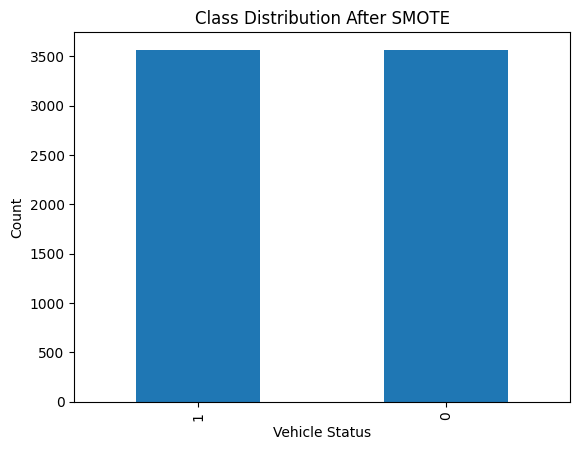

In [31]:
#smote

from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)
y_train_balanced.value_counts()
#plot
y_train_balanced.value_counts().plot(kind='bar')

plt.xlabel("Vehicle Status")
plt.ylabel("Count")
plt.title("Class Distribution After SMOTE")

plt.show()

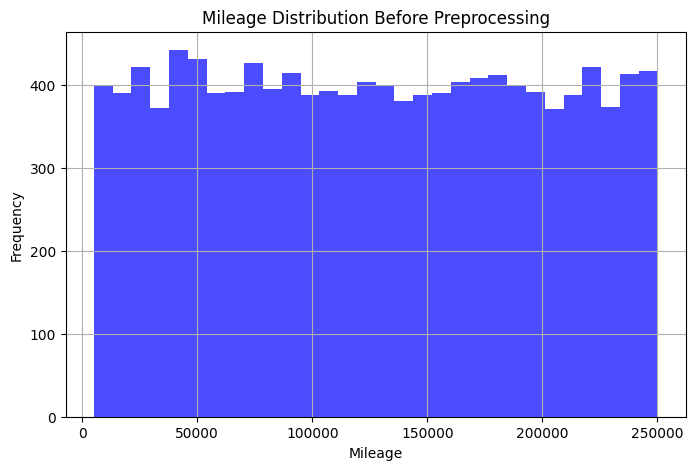

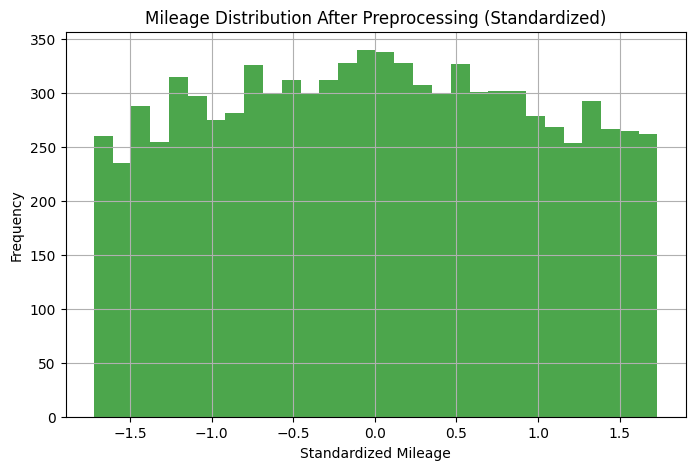

In [32]:
#Step 17: Visualize Distribution Before and After Preprocessing
# Load a fresh copy of the raw dataset to represent "Before"
df_original = pd.read_csv("carsensor.csv")

import matplotlib.pyplot as plt

# Before preprocessing
plt.figure(figsize=(8,5))
df_original['Mileage'].hist(bins=30, alpha=0.7, color='blue')
plt.title("Mileage Distribution Before Preprocessing")
plt.xlabel("Mileage")
plt.ylabel("Frequency")
plt.show()

# After preprocessing
plt.figure(figsize=(8,5))
df['Mileage'].hist(bins=30, alpha=0.7, color='green')
plt.title("Mileage Distribution After Preprocessing (Standardized)")
plt.xlabel("Standardized Mileage")
plt.ylabel("Frequency")
plt.show()

In [33]:
#Step 18: Compare Dataset Before and After Preprocessing
# We compute means only for numerical columns present in both datasets
common_num_cols = [col for col in num_cols if col in df.columns and col in df_original.columns]

comparison = pd.DataFrame({
    "Before (Raw Mean)": df_original[common_num_cols].mean(),
    "After (Processed Mean)": df[common_num_cols].mean()
})

comparison

,Before (Raw Mean),After (Processed Mean)
Vehicle_Age,6.510917,-0.006648
Mileage,127103.114750,0.002555
Engine_Temp,96.646583,0.039425
RPM,2032.028417,0.004385
Oil_Pressure,32.867917,-0.041673
Fuel_Consumption,12.743142,-0.015822
Battery_Voltage,12.252960,-0.003431
Brake_Pressure,34.866667,0.008787
Tire_Pressure,32.065167,0.004541


In [34]:
#Step 19: Save Cleaned Dataset as CSV
df.to_csv(
    "carsensor.csv",
    index=False
)
pd.read_csv("carsensor.csv").head()

,Vehicle_Type,Vehicle_Age,Mileage,Engine_Temp,RPM,Oil_Pressure,Fuel_Consumption,Battery_Voltage,Brake_Pressure,Tire_Pressure,Engine_Performance_Score,Vehicle_Efficiency,Average_Pressure,Vehicle_Status
0,Hatchback,1.012242,-1.679467,-1.570046,-1.066749,0.470386,1.384383,1.249491,-1.304526,-0.024930,-0.679434,-1.213143,-0.286357,1
1,Sedan,-0.439411,0.074088,-1.434027,-0.446663,0.166977,0.350863,-1.109227,-0.144275,0.364678,-0.311472,0.211152,0.129127,0
2,SUV,1.012242,0.443785,0.606251,0.668531,-1.046659,-0.402745,0.557600,1.347477,-0.414537,1.102711,1.101874,-0.037907,0
3,SUV,-0.439411,-1.024123,0.334214,0.877630,0.925499,-0.531935,-1.140676,-0.973026,-1.193753,2.625874,-1.925243,-0.413760,1
4,Sedan,-1.020071,-0.071858,0.742269,0.137372,1.228908,0.049420,-0.511685,1.513227,1.533502,0.185067,-1.453722,1.425212,1


In [35]:
X = df[['Vehicle_Age',
        'Mileage',
        'Engine_Temp',
        'RPM',
        'Oil_Pressure',
        'Battery_Voltage',
        'Brake_Pressure',
        'Tire_Pressure']]

y = df['Fuel_Consumption']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [37]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [38]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison.head()

,Actual,Predicted
8447,-1.371670,-1.198860
5361,0.781497,0.759245
4145,-0.704188,0.808803
7918,0.953750,-0.108978
2247,0.803028,0.030494


In [39]:
# Step 15.2: Separate Features and Target
X = df[['Vehicle_Age', 'Mileage', 'Engine_Temp', 'RPM', 'Oil_Pressure', 'Battery_Voltage', 'Brake_Pressure', 'Tire_Pressure']]
y = df['Fuel_Consumption']

# Step 15.3: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model Training
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Comparison
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

# Display the final comparison table
display(comparison.head())

,Actual,Predicted
8447,-1.371670,-1.198860
5361,0.781497,0.759245
4145,-0.704188,0.808803
7918,0.953750,-0.108978
2247,0.803028,0.030494
